# Chapitre 7 - Cours 1 : erreur d'apprentissage, erreur de test et compromis biais-variance

Ce premier notebook du chapitre 7 (*Model Assessment and Selection*) pose le vocabulaire
de base :

1. les différentes **erreurs** d'un modèle (erreur d'apprentissage, erreur de test
   conditionnelle, erreur espérée) et la figure 7.1 du livre ;
2. le découpage apprentissage / validation / test ;
3. la **décomposition biais-variance** (éq. (7.9) à (7.14) du livre), démontrée pas à pas
   et vérifiée par simulation ;
4. la reproduction de la figure 7.3 : biais, variance et erreur de prédiction pour les
   $k$ plus proches voisins et pour la régression linéaire sur sous-ensembles, en
   régression **et** en classification.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch07_selection as sel
set_style()

## 1. Notations : fonction de perte et erreurs

On dispose d'un **échantillon d'apprentissage**
$\mathcal T = \{(x_1, y_1), \dots, (x_N, y_N)\}$ tiré d'une loi jointe $F$ du couple
$(X, Y)$, et d'une règle de prédiction $\hat f$ construite à partir de $\mathcal T$.
Une **fonction de perte** $L(Y, \hat f(X))$ mesure le coût d'une erreur. Les deux
choix usuels en régression (éq. (7.1) du livre) sont

$$
L(Y, \hat f(X)) = (Y - \hat f(X))^2 \quad\text{(perte quadratique)}, \qquad
L(Y, \hat f(X)) = |Y - \hat f(X)| \quad\text{(perte absolue)}.
$$

Le livre distingue **trois** quantités qu'il ne faut pas confondre.

* L'**erreur de test conditionnelle** (ou erreur de généralisation), éq. (7.2) :
  $$\mathrm{Err}_{\mathcal T} = \mathbb E\big[L(Y, \hat f(X)) \,\big|\, \mathcal T\big].$$
  L'échantillon $\mathcal T$ est **fixé** ; l'espérance porte sur un nouveau couple
  $(X, Y)$ indépendant de $\mathcal T$.
* L'**erreur espérée**, éq. (7.3) :
  $$\mathrm{Err} = \mathbb E\big[L(Y, \hat f(X))\big] = \mathbb E\big[\mathrm{Err}_{\mathcal T}\big],$$
  qui moyenne en plus sur tous les échantillons d'apprentissage possibles.
* L'**erreur d'apprentissage**, éq. (7.4) :
  $$\overline{\mathrm{err}} = \frac1N \sum_{i=1}^N L(y_i, \hat f(x_i)),$$
  calculée sur les données mêmes qui ont servi à construire $\hat f$.

> **Intuition.** $\mathrm{Err}_{\mathcal T}$ est ce qui nous intéresse vraiment (la
> qualité du modèle que *nous* avons ajusté), $\mathrm{Err}$ est plus facile à étudier
> mathématiquement, et $\overline{\mathrm{err}}$ est la seule que l'on puisse calculer
> directement… mais elle est **trop optimiste** : un modèle très flexible peut
> rendre $\overline{\mathrm{err}}$ nulle tout en prédisant mal de nouvelles données.

Pour une réponse qualitative $G$ à $K$ classes, on estime des probabilités
$\hat p_k(x) = \widehat{\Pr}(G = k \mid X = x)$ et l'on classe avec
$\hat G(x) = \arg\max_k \hat p_k(x)$. Les pertes usuelles (éq. (7.5)-(7.6)) sont

$$
L(G, \hat G(X)) = I(G \neq \hat G(X)) \quad\text{(perte 0-1)}, \qquad
L(G, \hat p(X)) = -2 \log \hat p_G(X) \quad\text{(déviance, ou } -2\times\text{log-vraisemblance)}.
$$

Le facteur $-2$ rend la déviance égale à la perte quadratique dans le cas gaussien.

## 2. Figure 7.1 : erreur d'apprentissage et erreur de test

Pour reproduire l'esprit de la figure 7.1, nous simulons un modèle linéaire
$Y = X^T\beta + \varepsilon$ avec $p = 35$ prédicteurs gaussiens indépendants
$\mathcal N(0, 1)$, des coefficients décroissants $\beta_j = 0{,}9 \times 0{,}8^{\,j-1}$ et
un bruit $\varepsilon \sim \mathcal N(0, 1)$. Pour chacun de **100 échantillons
d'apprentissage de taille 50**, on ajuste par moindres carrés les modèles emboîtés
utilisant les $d$ premiers prédicteurs, $d = 0, 1, \dots, 35$ : $d$ mesure la
**complexité** du modèle.

Ici l'erreur de test conditionnelle se calcule **exactement**. Si $\hat\beta$ est
l'estimateur (complété par des zéros) et $X^0 \sim \mathcal N(0, I_p)$ est indépendant
de $\varepsilon^0$,

$$
\mathrm{Err}_{\mathcal T}
= \mathbb E\big[(X^{0T}\beta + \varepsilon^0 - X^{0T}\hat\beta)^2\big]
= \sigma^2 + (\beta - \hat\beta)^T \,\mathbb E[X^0 X^{0T}]\, (\beta - \hat\beta)
= \sigma^2 + \|\beta - \hat\beta\|^2,
$$

car le terme croisé est nul ($\varepsilon^0$ est centré et indépendant de $X^0$) et
$\mathbb E[X^0X^{0T}] = I_p$.

In [2]:
rng = np.random.RandomState(0)
N, p, sigma = 50, 35, 1.0
beta = 0.9 * 0.8 ** np.arange(p)
n_sets = 100
dims = np.arange(p + 1)

train_err = np.zeros((n_sets, p + 1))
test_err = np.zeros((n_sets, p + 1))
for s in range(n_sets):
    X = rng.randn(N, p)
    y = X @ beta + sigma * rng.randn(N)
    for d in dims:
        b = np.zeros(p)
        if d > 0:
            b[:d] = np.linalg.lstsq(X[:, :d], y, rcond=None)[0]
        train_err[s, d] = np.mean((y - X @ b) ** 2)
        test_err[s, d] = sigma ** 2 + np.sum((beta - b) ** 2)
print("d minimisant Err (moyenne des Err_T) :", dims[test_err.mean(0).argmin()])

d minimisant Err (moyenne des Err_T) : 9


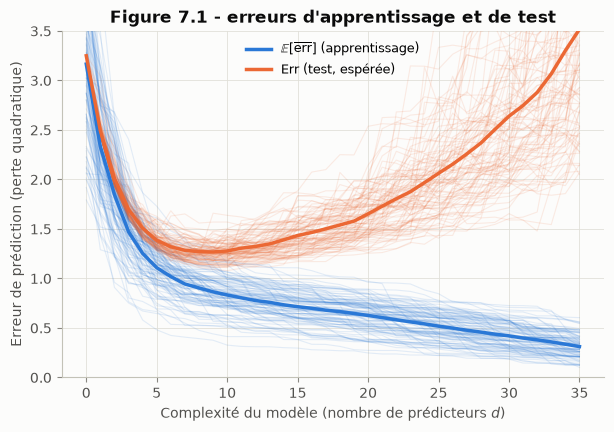

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for s in range(n_sets):
    ax.plot(dims, train_err[s], color=BLUE, alpha=0.12, lw=0.8)
    ax.plot(dims, test_err[s], color=ORANGE, alpha=0.12, lw=0.8)
ax.plot(dims, train_err.mean(0), color=BLUE, lw=2.5, label=r"$\mathbb{E}[\overline{\mathrm{err}}]$ (apprentissage)")
ax.plot(dims, test_err.mean(0), color=ORANGE, lw=2.5, label=r"$\mathrm{Err}$ (test, espérée)")
ax.set_ylim(0, 3.5)
ax.set_xlabel("Complexité du modèle (nombre de prédicteurs $d$)")
ax.set_ylabel("Erreur de prédiction (perte quadratique)")
ax.set_title("Figure 7.1 - erreurs d'apprentissage et de test")
ax.legend()
plt.show()

Les courbes fines montrent $\overline{\mathrm{err}}$ (bleu) et $\mathrm{Err}_{\mathcal T}$
(orange) pour chacun des 100 échantillons ; les courbes épaisses en sont les moyennes.

* L'erreur d'apprentissage **décroît toujours** avec $d$ : ajouter une variable ne
  peut qu'augmenter la qualité de l'ajustement aux données vues.
* L'erreur de test décroît d'abord (on réduit le **biais**), puis remonte fortement
  (la **variance** explose quand $d$ s'approche de $N$) : c'est le **surapprentissage**.
* Pour un $d$ fixé, $\mathrm{Err}_{\mathcal T}$ varie beaucoup d'un échantillon à
  l'autre : estimer l'erreur conditionnelle à partir d'un seul échantillon est difficile
  (section 7.12 du livre).

> **À retenir.** L'erreur d'apprentissage n'est **pas** un bon estimateur de l'erreur de
> test : elle est biaisée vers le bas, d'autant plus que le modèle est complexe. Tout le
> chapitre consiste à corriger ce biais, soit analytiquement (Cp, AIC, BIC…), soit par
> réutilisation des données (validation croisée, bootstrap).

## 3. Deux objectifs, trois échantillons

Le livre distingue deux tâches :

* **sélection de modèle** : estimer la performance de plusieurs modèles (ou valeurs d'un
  paramètre de réglage) pour choisir le meilleur ;
* **évaluation de modèle** : une fois le modèle final choisi, estimer son erreur de
  prédiction sur de nouvelles données.

Avec beaucoup de données, on découpe l'échantillon en trois parties, typiquement 50 %
pour l'**apprentissage**, 25 % pour la **validation** (choix du modèle) et 25 % pour le
**test** (évaluation finale, utilisé une seule fois, à la toute fin).

> **Remarque.** Réutiliser l'échantillon test pour choisir le modèle sous-estime l'erreur
> du modèle finalement retenu : on a choisi celui qui a eu « de la chance » sur ces
> données. Les méthodes du chapitre servent quand les données sont trop peu nombreuses
> pour un tel découpage.

## 4. La décomposition biais-variance

On suppose un modèle à bruit additif $Y = f(X) + \varepsilon$ avec
$\mathbb E(\varepsilon) = 0$, $\mathrm{Var}(\varepsilon) = \sigma_\varepsilon^2$ et
$\varepsilon$ indépendant de l'échantillon d'apprentissage. En un point $x_0$ fixé, on
note $\hat f(x_0)$ la prédiction : c'est une variable aléatoire, via l'échantillon
d'apprentissage. L'erreur de prédiction espérée en $x_0$ est

$$\mathrm{Err}(x_0) = \mathbb E\big[(Y - \hat f(x_0))^2 \,\big|\, X = x_0\big].$$

**Démonstration de (7.9).** On écrit $Y - \hat f(x_0)$ comme une somme de trois termes
en ajoutant et retranchant $f(x_0)$ et $\mathbb E\hat f(x_0)$ :

$$
Y - \hat f(x_0) = \underbrace{\varepsilon}_{A}
 + \underbrace{f(x_0) - \mathbb E\hat f(x_0)}_{B}
 + \underbrace{\mathbb E\hat f(x_0) - \hat f(x_0)}_{C}.
$$

* $A$ est centré et indépendant de $C$ (le bruit du nouveau point ne dépend pas de
  l'échantillon d'apprentissage) ;
* $B$ est une constante (déterministe) ;
* $C$ est centré par construction.

En développant $(A+B+C)^2$ et en prenant l'espérance, les doubles produits s'annulent :
$\mathbb E[AB] = B\,\mathbb E[A] = 0$, $\mathbb E[BC] = B\,\mathbb E[C] = 0$ et
$\mathbb E[AC] = \mathbb E[A]\,\mathbb E[C] = 0$ par indépendance. Il reste

$$
\begin{aligned}
\mathrm{Err}(x_0) &= \sigma_\varepsilon^2 + \big[\mathbb E\hat f(x_0) - f(x_0)\big]^2
  + \mathbb E\big[\hat f(x_0) - \mathbb E\hat f(x_0)\big]^2 \\
&= \underbrace{\sigma_\varepsilon^2}_{\text{erreur irréductible}}
 + \underbrace{\mathrm{Biais}^2\big(\hat f(x_0)\big)}_{\text{biais au carré}}
 + \underbrace{\mathrm{Var}\big(\hat f(x_0)\big)}_{\text{variance}}.
\end{aligned}
$$

C'est l'éq. (7.9) du livre.

> **Intuition.** L'erreur irréductible ne dépend pas de la méthode : même la vraie
> fonction $f$ la commet. Le biais mesure l'écart entre la prédiction **moyenne** et la
> vérité ; la variance mesure la dispersion de la prédiction autour de sa moyenne quand on
> change d'échantillon. En général, plus le modèle est complexe, plus le biais diminue et
> plus la variance augmente.

### 4.1 Cas des $k$ plus proches voisins (éq. (7.10))

On suppose les entrées $x_i$ **fixées** ; seules les réponses $y_i = f(x_i) + \varepsilon_i$
sont aléatoires. L'estimateur des $k$ plus proches voisins est
$\hat f_k(x_0) = \frac1k \sum_{\ell=1}^k y_{(\ell)}$, où $x_{(1)}, \dots, x_{(k)}$ sont
les $k$ points d'apprentissage les plus proches de $x_0$. Par linéarité de l'espérance,
$\mathbb E\hat f_k(x_0) = \frac1k\sum_\ell f(x_{(\ell)})$ ; et comme les $\varepsilon_i$
sont indépendants de variance $\sigma_\varepsilon^2$,
$\mathrm{Var}\,\hat f_k(x_0) = \frac{1}{k^2}\cdot k\sigma_\varepsilon^2 = \sigma_\varepsilon^2/k$.
D'où

$$
\mathrm{Err}(x_0) = \sigma_\varepsilon^2 + \Big[f(x_0) - \frac1k\sum_{\ell=1}^k f(x_{(\ell)})\Big]^2
  + \frac{\sigma_\varepsilon^2}{k}.
$$

Vérifions cette formule par simulation : $f(x) = \sin(4x)$ sur $[0, 1]$, $N = 40$ entrées
fixées, $\sigma_\varepsilon = 0{,}5$, point $x_0 = 0{,}3$.

In [4]:
rng = np.random.RandomState(0)
N, sig = 40, 0.5
x = np.sort(rng.rand(N))
f = lambda t: np.sin(4 * t)
x0 = 0.3
ks = np.arange(1, 31)
n_rep = 20000
Y = f(x) + sig * rng.randn(n_rep, N)          # n_rep échantillons de réponses
Y0 = f(x0) + sig * rng.randn(n_rep)           # réponses test indépendantes en x0
order = np.argsort(np.abs(x - x0), kind="stable")

err_mc, err_th, bias2, var = [], [], [], []
for k in ks:
    nb = order[:k]
    fhat = Y[:, nb].mean(1)
    err_mc.append(np.mean((Y0 - fhat) ** 2))
    bias2.append((f(x0) - f(x[nb]).mean()) ** 2)
    var.append(sig ** 2 / k)
    err_th.append(sig ** 2 + bias2[-1] + var[-1])
err_mc, err_th = np.array(err_mc), np.array(err_th)
print("écart max entre simulation et formule (7.10) : %.4f" % np.abs(err_mc - err_th).max())

écart max entre simulation et formule (7.10) : 0.0044


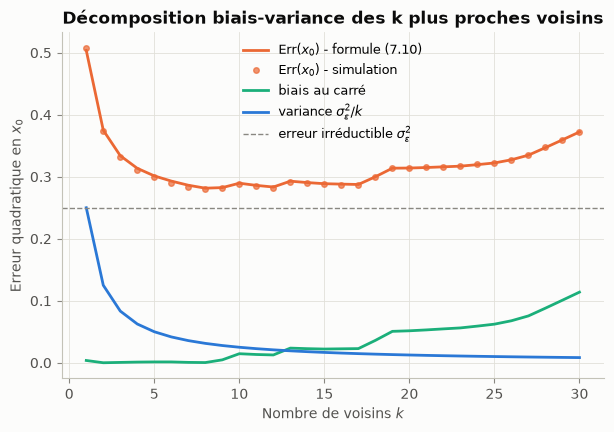

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, err_th, color=ORANGE, label=r"$\mathrm{Err}(x_0)$ - formule (7.10)")
ax.plot(ks, err_mc, "o", color=ORANGE, ms=4, alpha=0.7, label=r"$\mathrm{Err}(x_0)$ - simulation")
ax.plot(ks, bias2, color=COLORS[2], label="biais au carré")
ax.plot(ks, var, color=BLUE, label=r"variance $\sigma_\varepsilon^2/k$")
ax.axhline(sig ** 2, color=GRAY, ls="--", lw=1, label=r"erreur irréductible $\sigma_\varepsilon^2$")
ax.set_xlabel("Nombre de voisins $k$")
ax.set_ylabel("Erreur quadratique en $x_0$")
ax.set_title("Décomposition biais-variance des k plus proches voisins")
ax.legend()
plt.show()

La simulation coïncide avec la formule. Quand $k$ augmente, la variance $\sigma^2_\varepsilon/k$
décroît, mais le biais croît car on moyenne des valeurs de $f$ de plus en plus éloignées
de $f(x_0)$ : la complexité est **inversement** liée à $k$.

### 4.2 Cas du modèle linéaire (éq. (7.11)-(7.12))

Pour un ajustement par moindres carrés à $p$ paramètres,
$\hat f_p(x_0) = x_0^T(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y = h(x_0)^T\mathbf y$
avec $h(x_0) = \mathbf X(\mathbf X^T\mathbf X)^{-1}x_0 \in \mathbb R^N$. La prédiction est
une combinaison linéaire des $y_i$, donc
$\mathrm{Var}\,\hat f_p(x_0) = \|h(x_0)\|^2 \sigma_\varepsilon^2$ et

$$\mathrm{Err}(x_0) = \sigma_\varepsilon^2 + \big[f(x_0) - \mathbb E\hat f_p(x_0)\big]^2 + \|h(x_0)\|^2\sigma_\varepsilon^2. \tag{7.11}$$

**Variance moyenne aux points d'apprentissage.** Si $x_0 = x_i$, alors $h(x_i)$ est la
$i$-ème colonne de la matrice chapeau $\mathbf H = \mathbf X(\mathbf X^T\mathbf X)^{-1}\mathbf X^T$.
Comme $\mathbf H$ est symétrique et idempotente ($\mathbf H^2 = \mathbf H$),

$$
\sum_{i=1}^N \|h(x_i)\|^2 = \sum_{i,j} H_{ji}^2 = \mathrm{trace}(\mathbf H^T\mathbf H)
 = \mathrm{trace}(\mathbf H) = p,
$$

la dernière égalité car $\mathbf H$ est le projecteur orthogonal sur un espace de
dimension $p$. En moyennant (7.11) sur les $x_i$, on obtient l'**erreur intra-échantillon**

$$\frac1N\sum_{i=1}^N \mathrm{Err}(x_i) = \sigma_\varepsilon^2 + \frac1N\sum_{i=1}^N\big[f(x_i) - \mathbb E\hat f(x_i)\big]^2 + \frac pN\sigma_\varepsilon^2. \tag{7.12}$$

In [6]:
rng = np.random.RandomState(1)
Xd = rng.randn(60, 7)
H = sel.hat_matrix(Xd)                 # 7 prédicteurs + constante : p = 8
print("somme des ||h(x_i)||^2 =", round(np.sum(H ** 2), 10), "; trace(H) =", round(np.trace(H), 10))

somme des ||h(x_i)||^2 = 8.0 ; trace(H) = 8.0


### 4.3 Biais du modèle et biais d'estimation (éq. (7.14))

Notons $\beta_* = \arg\min_\beta \mathbb E\big[(f(X) - X^T\beta)^2\big]$ la meilleure
approximation linéaire de $f$ (éq. (7.13)). En ajoutant et retranchant $x_0^T\beta_*$, le
biais au carré moyen se décompose en

$$
\mathbb E_{x_0}\big[f(x_0) - \mathbb E\hat f_\alpha(x_0)\big]^2
= \underbrace{\mathbb E_{x_0}\big[f(x_0) - x_0^T\beta_*\big]^2}_{\text{biais de modèle}^2}
+ \underbrace{\mathbb E_{x_0}\big[x_0^T\beta_* - \mathbb E\, x_0^T\hat\beta_\alpha\big]^2}_{\text{biais d'estimation}^2},
$$

le double produit étant nul grâce aux équations normales qui caractérisent $\beta_*$
($\mathbb E[X(f(X) - X^T\beta_*)] = 0$). Pour les moindres carrés, le biais d'estimation
est nul ; une méthode régularisée (ridge) accepte un biais d'estimation positif en
échange d'une variance plus faible. Le biais de modèle ne diminue qu'en enrichissant la
classe de modèles (interactions, transformations).

## 5. Figure 7.3 : biais, variance et erreur en régression et en classification

Le livre considère $N = 80$ observations et $20$ prédicteurs uniformes sur $[0, 1]^{20}$,
**sans bruit** ($\sigma_\varepsilon = 0$), dans deux situations :

* **gauche** : $Y = I(X_1 > 1/2)$, ajusté par les $k$ plus proches voisins ;
* **droite** : $Y = I\big(\sum_{j=1}^{10} X_j > 5\big)$, ajusté par régression linéaire
  sur un sous-ensemble de $p$ variables.

On calcule l'erreur de prédiction, le biais au carré et la variance sur un grand
échantillon test, en moyennant sur de nombreux échantillons d'apprentissage. En
classification, on prédit $\hat G(x) = I(\hat f(x) > 1/2)$ et l'on mesure la perte 0-1.

> **Remarque (choix d'implémentation).** Le livre utilise le **meilleur sous-ensemble**
> de taille $p$ ; parmi 20 variables, cela représente jusqu'à $\binom{20}{10} \approx 185\,000$
> ajustements par taille et par échantillon, trop coûteux ici. Nous utilisons la
> sélection **pas à pas ascendante** (chapitre 3), qui en est une approximation gloutonne
> et donne des courbes très semblables.

In [7]:
rng = np.random.RandomState(0)
N, P, n_test, n_rep = 80, 20, 1000, 100
Xte = rng.rand(n_test, P)
f_knn = lambda X: (X[:, 0] > 0.5).astype(float)
f_lin = lambda X: (X[:, :10].sum(1) > 5).astype(float)
k_grid = np.array([1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50])
p_grid = np.arange(1, P + 1)

pred_knn = np.zeros((n_rep, len(k_grid), n_test))
pred_lin = np.zeros((n_rep, len(p_grid), n_test))
for r in range(n_rep):
    X = rng.rand(N, P)
    # k plus proches voisins : on trie une fois les distances test -> apprentissage
    d2 = ((Xte[:, None, :] - X[None, :, :]) ** 2).sum(-1)
    nn = np.argsort(d2, axis=1)
    csum = np.cumsum(f_knn(X)[nn], axis=1)
    pred_knn[r] = (csum[:, k_grid - 1] / k_grid).T
    # régression linéaire sur sous-ensembles (pas à pas ascendant)
    y = f_lin(X)
    order = sel.forward_stepwise(X, y)
    for j, pp in enumerate(p_grid):
        pred_lin[r, j] = sel.ols_fit_predict(X[:, order[:pp]], y, Xte[:, order[:pp]])